In [1]:
!pip install -q diffusers==0.42.1 torchmetrics torch-fidelity lpips
import glob, os, shutil, sys, zipfile
def find(name):
    h = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True)); return h[0] if h else None

# rebuild the M2 folder the code expects: M2/protocol + M2/splits
M2 = "/kaggle/working/M2"
shutil.copytree(os.path.dirname(find("m2_protocol.py")), f"{M2}/protocol", dirs_exist_ok=True)
shutil.copytree(os.path.dirname(find("dev_500.csv")), f"{M2}/splits", dirs_exist_ok=True)
assert find("m2_scoring.py"), "m2_scoring.py not attached yet"
shutil.copy(find("m2_scoring.py"), f"{M2}/protocol/")

# your generation log: merge every m2/ folder (or unextracted zip) into one place
SRC = "/tmp/m2src"
for d in glob.glob("/kaggle/input/**/m2", recursive=True):
    if os.path.isdir(d): shutil.copytree(d, SRC, dirs_exist_ok=True)
if not os.path.exists(f"{SRC}/images.csv"):
    for z in glob.glob("/kaggle/input/**/*.zip", recursive=True):
        zipfile.ZipFile(z).extractall("/tmp/unz")
    for d in glob.glob("/tmp/unz/**/m2", recursive=True): shutil.copytree(d, SRC, dirs_exist_ok=True)
assert os.path.exists(f"{SRC}/images.csv"), "images not attached yet"

sys.path.insert(0, f"{M2}/protocol")
import m2_protocol as m2, m2_scoring as sc, pandas as pd
WORK, PHOTOS = "/kaggle/working/m2", "/tmp/coco_photos"
SCORES = f"{WORK}/scores"
print(m2.PROTOCOL_VERSION, sc.SCORING_VERSION, "| images found:", len(glob.glob(f"{SRC}/images/**/*.png", recursive=True)))

AssertionError: images not attached yet

In [2]:
sys.path.insert(0, f"{M2}/protocol")
import m2_protocol as m2, m2_scoring as sc, pandas as pd
WORK, PHOTOS = "/kaggle/working/m2", "/tmp/coco_photos"
SCORES = f"{WORK}/scores"
print(m2.PROTOCOL_VERSION, sc.SCORING_VERSION)

m2-v1 m2-score-v1


In [3]:
pipe = m2.load_pipeline()
m2.smoke_check(pipe)
log = m2.RunLog(WORK, owner="Mukul", axis="noise schedule")
m2.run_config(pipe, m2.ANCHOR, "dev_500", log,
              notes="anchor reproduced for paired comparison with the 10-step schedules; identical to Tanmayi's by protocol")
import torch; del pipe; torch.cuda.empty_cache()

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

protocol m2-v1 (8b9a21852c0f), torch 2.11.0+cu130
first dev caption_idx 3669, noise sum 36.4438: OK
anchor timesteps [958, 925, 892] ... [34, 1] (30): OK
  3669: mean pixel 117.28, flagged False, 9.11 s
  15909: mean pixel 103.99, flagged False, 4.33 s
  2784: mean pixel 98.55, flagged False, 4.34 s
  458: mean pixel 111.60, flagged False, 4.37 s
  22569: mean pixel 128.90, flagged False, 4.39 s
  11004: mean pixel 125.05, flagged False, 4.41 s
  13919: mean pixel 103.43, flagged False, 4.43 s
  21516: mean pixel 122.87, flagged False, 4.48 s
  6324: mean pixel 108.73, flagged False, 4.50 s
  13702: mean pixel 103.66, flagged False, 4.49 s


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s30-g7.5 on dev_500: 50/500 prompts, 4.93 s/image
ddim-leading-s30-g7.5 on dev_500: 100/500 prompts, 4.98 s/image
ddim-leading-s30-g7.5 on dev_500: 150/500 prompts, 5.00 s/image
ddim-leading-s30-g7.5 on dev_500: 200/500 prompts, 5.01 s/image
ddim-leading-s30-g7.5 on dev_500: 250/500 prompts, 5.01 s/image
ddim-leading-s30-g7.5 on dev_500: 300/500 prompts, 5.02 s/image
ddim-leading-s30-g7.5 on dev_500: 350/500 prompts, 5.02 s/image


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s30-g7.5 on dev_500: 400/500 prompts, 5.02 s/image
ddim-leading-s30-g7.5 on dev_500: 450/500 prompts, 5.03 s/image
ddim-leading-s30-g7.5 on dev_500: 500/500 prompts, 5.03 s/image
ddim-leading-s30-g7.5 on dev_500: done, 500 images, 2 flagged, 5.028 s/image


In [4]:
SRC = "/tmp/m2src"
for d in glob.glob("/kaggle/input/**/m2", recursive=True):
    if os.path.isdir(d): shutil.copytree(d, SRC, dirs_exist_ok=True)
if not os.path.exists(f"{SRC}/images.csv"):
    for z in glob.glob("/kaggle/input/**/*.zip", recursive=True):
        zipfile.ZipFile(z).extractall("/tmp/unz")
    for d in glob.glob("/tmp/unz/**/m2", recursive=True): shutil.copytree(d, SRC, dirs_exist_ok=True)
print("images found:", len(glob.glob(f"{SRC}/images/**/*.png", recursive=True)))

images found: 0


In [1]:
!pip install -q diffusers==0.42.1 torchmetrics torch-fidelity lpips
import glob, os, shutil, sys, zipfile
def find(name):
    h = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True)); return h[0] if h else None
M2 = "/kaggle/working/M2"
shutil.copytree(os.path.dirname(find("m2_protocol.py")), f"{M2}/protocol", dirs_exist_ok=True)
shutil.copytree(os.path.dirname(find("dev_500.csv")), f"{M2}/splits", dirs_exist_ok=True)
shutil.copy(find("m2_scoring.py"), f"{M2}/protocol/")
sys.path.insert(0, f"{M2}/protocol")
import m2_protocol as m2, m2_scoring as sc, pandas as pd
WORK, PHOTOS = "/kaggle/working/m2", "/tmp/coco_photos"
SCORES = f"{WORK}/scores"
print(m2.PROTOCOL_VERSION, sc.SCORING_VERSION)
print("anchor images:", len(glob.glob(f"{WORK}/images/**/*.png", recursive=True)))
print("inputs:", sorted({p.split('/')[4] for p in glob.glob('/kaggle/input/datasets/*/*')}))

m2-v1 m2-score-v1
anchor images: 0
inputs: ['abecklas', 'mukuls0']


In [2]:
pipe = m2.load_pipeline()
m2.smoke_check(pipe)
log = m2.RunLog(WORK, owner="Mukul", axis="noise schedule (Kaggle T4, torch 2.11)")
SCHED = ("leading", "trailing", "karras", "ays")

m2.run_config(pipe, m2.ANCHOR, "dev_500", log, notes="anchor, same environment as the schedule runs")
for s in SCHED:
    m2.run_config(pipe, m2.GenConfig("dpmpp2m", s, 10), "dev_500", log)
for s in SCHED:
    m2.run_config(pipe, m2.GenConfig("dpmpp2m", s, 10), "dev_500", log, seed_ids=(1,), first=100)
for s in SCHED:
    m2.run_config(pipe, m2.GenConfig("dpmpp2m", s, 30), "dev_500", log, first=200)
import torch; del pipe; torch.cuda.empty_cache()

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

... (35 outputs left out)

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


dpmpp2m-ays-s10-g7.5 on dev_500: 50/100 prompts, 1.99 s/image


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


dpmpp2m-ays-s10-g7.5 on dev_500: 100/100 prompts, 2.00 s/image
dpmpp2m-ays-s10-g7.5 on dev_500: done, 600 images, 3 flagged, 1.998 s/image
dpmpp2m-leading-s30-g7.5 on dev_500: 50/200 prompts, 5.46 s/image
dpmpp2m-leading-s30-g7.5 on dev_500: 100/200 prompts, 5.45 s/image
dpmpp2m-leading-s30-g7.5 on dev_500: 150/200 prompts, 5.46 s/image
dpmpp2m-leading-s30-g7.5 on dev_500: 200/200 prompts, 5.45 s/image
dpmpp2m-leading-s30-g7.5 on dev_500: done, 200 images, 0 flagged, 5.453 s/image
dpmpp2m-trailing-s30-g7.5 on dev_500: 50/200 prompts, 5.46 s/image
dpmpp2m-trailing-s30-g7.5 on dev_500: 100/200 prompts, 5.46 s/image
dpmpp2m-trailing-s30-g7.5 on dev_500: 150/200 prompts, 5.45 s/image
dpmpp2m-trailing-s30-g7.5 on dev_500: 200/200 prompts, 5.45 s/image
dpmpp2m-trailing-s30-g7.5 on dev_500: done, 200 images, 0 flagged, 5.454 s/image
dpmpp2m-karras-s30-g7.5 on dev_500: 50/200 prompts, 5.44 s/image
dpmpp2m-karras-s30-g7.5 on dev_500: 100/200 prompts, 5.45 s/image
dpmpp2m-karras-s30-g7.5 on dev_

In [3]:
imgs = sc.read_logs([(f"{WORK}/images.csv", f"{WORK}/images")])
imgs.groupby(["config_id", "seed_id"]).agg(images=("key", "size"), flagged=("flagged", "sum"))

images  flagged
config_id                 seed_id                 
ddim-leading-s30-g7.5     0           500        2
dpmpp2m-ays-s10-g7.5      0           500        1
                          1           100        2
dpmpp2m-ays-s30-g7.5      0           200        0
dpmpp2m-karras-s10-g7.5   0           500        4
                          1           100        1
dpmpp2m-karras-s30-g7.5   0           200        0
dpmpp2m-leading-s10-g7.5  0           500        5
                          1           100        1
dpmpp2m-leading-s30-g7.5  0           200        0
dpmpp2m-trailing-s10-g7.5 0           500        3
                          1           100        2
dpmpp2m-trailing-s30-g7.5 0           200        0

In [4]:
sc.download_coco(list(sc.load_split("ref_2000_v2").image_id) + list(sc.load_split("dev_500").image_id), PHOTOS)
scorers = sc.Scorers()
sc.reference_features("ref_2000_v2", PHOTOS, SCORES, scorers)
sc.score_real_photos("dev_500", PHOTOS, SCORES, scorers)
real = sc.load_objects(SCORES, "dev_500").query("config_id == 'real_photo'")
r, lo, hi, n = sc.recall(real, "real_photo", "dev_500")
print(f"recall ceiling on real photos: {r:.1%} [{lo:.1%}, {hi:.1%}] of {n} objects")

2500 photos in /tmp/coco_photos


Downloading: "https://github.com/toshas/torch-fidelity/releases/download/v0.2.0/weights-inception-2015-12-05-6726825d.pth" to /root/.cache/torch/hub/checkpoints/weights-inception-2015-12-05-6726825d.pth
100%|██████████| 91.2M/91.2M [00:00<00:00, 147MB/s] 


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

... (15 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/460 [00:00<?, ?B/s]

reference features: 2000 photos -> /kaggle/working/m2/scores/features/reference__ref_2000_v2.npz


OSError: Cannot save file into a non-existent directory: '/kaggle/working/m2/scores/objects'

In [5]:
import os
for sub in ("objects", "images", "features", "diversity"):
    os.makedirs(f"{SCORES}/{sub}", exist_ok=True)

sc.score_real_photos("dev_500", PHOTOS, SCORES, scorers)
real = sc.load_objects(SCORES, "dev_500").query("config_id == 'real_photo'")
r, lo, hi, n = sc.recall(real, "real_photo", "dev_500")
print(f"recall ceiling on real photos: {r:.1%} [{lo:.1%}, {hi:.1%}] of {n} objects")

real photos of dev_500: 559 object verdicts -> /kaggle/working/m2/scores/objects/dev_500__real_photo.csv
recall ceiling on real photos: 98.9% [98.0%, 99.6%] of 559 objects


In [6]:
sc.score_log(imgs, SCORES, scorers, splits=["dev_500"])
sc.score_diversity(imgs, SCORES, scorers)

dev_500__ddim-leading-s30-g7.5: 16/498 images
dev_500__ddim-leading-s30-g7.5: 176/498 images
dev_500__ddim-leading-s30-g7.5: 336/498 images
dev_500__ddim-leading-s30-g7.5: 496/498 images
dev_500__ddim-leading-s30-g7.5: 500 images, 498 scored, 2 flagged and left out, 558 object verdicts
dev_500__dpmpp2m-leading-s10-g7.5: 16/594 images
dev_500__dpmpp2m-leading-s10-g7.5: 176/594 images
dev_500__dpmpp2m-leading-s10-g7.5: 336/594 images
dev_500__dpmpp2m-leading-s10-g7.5: 496/594 images
dev_500__dpmpp2m-leading-s10-g7.5: 600 images, 594 scored, 6 flagged and left out, 659 object verdicts
dev_500__dpmpp2m-trailing-s10-g7.5: 16/595 images
dev_500__dpmpp2m-trailing-s10-g7.5: 176/595 images
dev_500__dpmpp2m-trailing-s10-g7.5: 336/595 images
dev_500__dpmpp2m-trailing-s10-g7.5: 496/595 images
dev_500__dpmpp2m-trailing-s10-g7.5: 600 images, 595 scored, 5 flagged and left out, 660 object verdicts
dev_500__dpmpp2m-karras-s10-g7.5: 16/595 images
dev_500__dpmpp2m-karras-s10-g7.5: 176/595 images
dev_500

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 213MB/s]  
/kaggle/working/M2/protocol/m2_scoring.py:255: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  t = lambda im: (torch.from_numpy(np.asarray(im)).permute(2, 0, 1)[None].float() / 127.5 - 1).to(self.device)  # noqa: E731


dev_500__dpmpp2m-leading-s10-g7.5: diversity on 98 caption pairs
dev_500__dpmpp2m-trailing-s10-g7.5: diversity on 98 caption pairs
dev_500__dpmpp2m-karras-s10-g7.5: diversity on 98 caption pairs
dev_500__dpmpp2m-ays-s10-g7.5: diversity on 98 caption pairs


In [7]:
SCHED = ("leading", "trailing", "karras", "ays"); ANCHOR = "ddim-leading-s30-g7.5"
S10 = [f"dpmpp2m-{s}-s10-g7.5" for s in SCHED]; S30 = [f"dpmpp2m-{s}-s30-g7.5" for s in SCHED]
first200 = sc.load_split("dev_500").caption_idx.head(200).astype(str).tolist()
cols = ["config_id", "images", "flagged", "objects", "recall", "recall_lo", "recall_hi", "clipscore", "kid", "kid_lo", "kid_hi", "fid", "lpips", "sec_per_image"]
show = lambda t: display(t[[c for c in cols if c in t]].round(3))

t500 = sc.summary_table(SCORES, split="dev_500", configs=S10 + [ANCHOR])                # schedules + anchor, all 500
t200 = sc.summary_table(SCORES, split="dev_500", configs=S10 + S30, keys=first200)      # 10 vs 30 steps, same 200
show(t500); show(t200)

obj, ims0 = sc.load_objects(SCORES, "dev_500"), sc.load_images(SCORES, "dev_500").query("seed_id == 0")
f_ref, r_anchor, rows = sc.load_reference(SCORES), sc.recall(obj, ANCHOR, "dev_500")[0], []
pairs = ([(a, ANCHOR, None) for a in S10] + [(a, S10[0], None) for a in S10[1:]]
         + [(b, a, first200) for a, b in zip(S10, S30)])
for a, b, keys in pairs:
    dr = sc.paired_recall_diff(obj, a, b, "dev_500", keys=keys)
    dc = sc.paired_mean_diff(ims0, a, b, "clipscore", keys=keys)
    dk = sc.paired_kid_diff(SCORES, "dev_500", a, b, f_ref, keys=keys)
    rows.append({"a": a, "vs": b, "captions": "first 200" if keys else "all 500",
                 "share_of_anchor_recall": sc.recall(obj, a, "dev_500")[0] / r_anchor if b == ANCHOR else None,
                 "recall_diff": dr[0], "r_lo": dr[1], "r_hi": dr[2], "clip_diff": dc[0], "c_lo": dc[1], "c_hi": dc[2],
                 "kid_diff": dk[0], "k_lo": dk[1], "k_hi": dk[2]})
paired = pd.DataFrame(rows)
for t, n in ((t500, "schedules_500"), (t200, "s10_vs_s30_200"), (paired, "paired")):
    t.to_csv(f"{SCORES}/mukul_{n}.csv", index=False)
paired.round(3)

,config_id,images,flagged,objects,recall,recall_lo,recall_hi,clipscore,kid,kid_lo,kid_hi,fid,lpips,sec_per_image
0,ddim-leading-s30-g7.5,500,2,558,0.939,0.920,0.958,26.778,4.413,3.449,5.604,85.052,NaN,5.441
1,dpmpp2m-ays-s10-g7.5,500,1,558,0.932,0.911,0.952,26.625,5.782,4.636,6.999,86.058,0.759,1.999
2,dpmpp2m-karras-s10-g7.5,500,4,554,0.931,0.909,0.952,26.687,4.730,3.707,5.901,84.460,0.761,1.995
3,dpmpp2m-leading-s10-g7.5,500,5,553,0.933,0.910,0.953,26.870,4.483,3.754,5.409,87.346,0.761,1.996
4,dpmpp2m-trailing-s10-g7.5,500,3,556,0.930,0.907,0.950,26.754,6.403,5.496,7.404,87.409,0.777,1.998


,config_id,images,flagged,objects,recall,recall_lo,recall_hi,clipscore,kid,kid_lo,kid_hi,fid,lpips,sec_per_image
0,dpmpp2m-ays-s10-g7.5,200,0,221,0.923,0.887,0.956,26.574,5.319,3.884,7.267,137.084,0.759,1.997
1,dpmpp2m-ays-s30-g7.5,200,0,221,0.928,0.893,0.959,26.652,5.101,3.331,7.382,134.821,NaN,5.433
2,dpmpp2m-karras-s10-g7.5,200,1,219,0.945,0.911,0.974,26.761,4.418,3.040,6.013,135.055,0.761,1.995
3,dpmpp2m-karras-s30-g7.5,200,0,221,0.928,0.890,0.959,26.672,5.049,3.329,7.270,135.509,NaN,5.448
4,dpmpp2m-leading-s10-g7.5,200,3,217,0.931,0.895,0.962,26.878,4.121,2.977,5.375,140.861,0.761,1.994
5,dpmpp2m-leading-s30-g7.5,200,0,221,0.928,0.892,0.960,26.620,4.767,3.460,6.617,136.970,NaN,5.453
6,dpmpp2m-trailing-s10-g7.5,200,0,221,0.937,0.901,0.969,26.866,6.367,5.070,7.968,138.222,0.777,2.000
7,dpmpp2m-trailing-s30-g7.5,200,0,221,0.941,0.908,0.969,26.782,5.415,3.968,7.356,136.171,NaN,5.454


,a,vs,captions,share_of_anchor_recall,recall_diff,r_lo,r_hi,clip_diff,c_lo,c_hi,kid_diff,k_lo,k_hi
0,dpmpp2m-leading-s10-g7.5,ddim-leading-s30-g7.5,all 500,0.994,-0.005,-0.018,0.007,0.124,-0.098,0.338,0.034,-0.786,0.731
1,dpmpp2m-trailing-s10-g7.5,ddim-leading-s30-g7.5,all 500,0.990,-0.009,-0.027,0.007,-0.010,-0.204,0.178,1.980,1.222,2.744
2,dpmpp2m-karras-s10-g7.5,ddim-leading-s30-g7.5,all 500,0.992,-0.009,-0.026,0.007,-0.071,-0.283,0.141,0.304,-0.484,1.161
3,dpmpp2m-ays-s10-g7.5,ddim-leading-s30-g7.5,all 500,0.992,-0.007,-0.023,0.009,-0.150,-0.358,0.054,1.368,0.574,2.110
4,dpmpp2m-trailing-s10-g7.5,dpmpp2m-leading-s10-g7.5,all 500,NaN,-0.004,-0.023,0.016,-0.118,-0.369,0.110,1.908,1.197,2.616
5,dpmpp2m-karras-s10-g7.5,dpmpp2m-leading-s10-g7.5,all 500,NaN,-0.002,-0.020,0.016,-0.170,-0.415,0.087,0.214,-0.627,1.179
6,dpmpp2m-ays-s10-g7.5,dpmpp2m-leading-s10-g7.5,all 500,NaN,-0.002,-0.020,0.016,-0.271,-0.498,-0.048,1.281,0.506,2.151
7,dpmpp2m-leading-s30-g7.5,dpmpp2m-leading-s10-g7.5,first 200,NaN,-0.005,-0.033,0.024,-0.263,-0.610,0.076,0.555,-0.620,1.923
8,dpmpp2m-trailing-s30-g7.5,dpmpp2m-trailing-s10-g7.5,first 200,NaN,0.005,-0.019,0.027,-0.085,-0.373,0.182,-0.952,-2.225,0.557
9,dpmpp2m-karras-s30-g7.5,dpmpp2m-karras-s10-g7.5,first 200,NaN,-0.018,-0.046,0.009,-0.080,-0.369,0.222,0.655,-0.624,2.006


In [8]:
pipe = m2.load_pipeline()
log = m2.RunLog(WORK, owner="Mukul", axis="noise schedule (Kaggle T4, torch 2.11)")
for cfg in (m2.ANCHOR, m2.GenConfig("dpmpp2m", "leading", 10)):
    m2.run_config(pipe, cfg, "dev_500", log, seed_ids=(1, 2), first=200)
import torch; del pipe; torch.cuda.empty_cache()

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s30-g7.5 on dev_500: 50/200 prompts, 5.46 s/image


Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


ddim-leading-s30-g7.5 on dev_500: 100/200 prompts, 5.45 s/image
ddim-leading-s30-g7.5 on dev_500: 150/200 prompts, 5.45 s/image
ddim-leading-s30-g7.5 on dev_500: 200/200 prompts, 5.45 s/image
ddim-leading-s30-g7.5 on dev_500: done, 900 images, 4 flagged, 5.446 s/image
dpmpp2m-leading-s10-g7.5 on dev_500: 50/200 prompts, 1.99 s/image
dpmpp2m-leading-s10-g7.5 on dev_500: 100/200 prompts, 1.99 s/image
dpmpp2m-leading-s10-g7.5 on dev_500: 150/200 prompts, 2.00 s/image
dpmpp2m-leading-s10-g7.5 on dev_500: 200/200 prompts, 1.99 s/image
dpmpp2m-leading-s10-g7.5 on dev_500: done, 900 images, 6 flagged, 1.995 s/image


In [9]:
import os, json, glob, math, random, time, zipfile, urllib.request
import numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModel, T5EncoderModel, CLIPTokenizer, CLIPTextModel
DEV, OUT = "cuda", "/kaggle/working/connector"; os.makedirs(OUT, exist_ok=True)
CFG = dict(encoder="bert-base-uncased", n_train=100_000, n_heldout=2_000, batch=128, lr=3e-4, warmup=500,
           max_steps=8000, max_minutes=90, log_every=50, eval_every=250, layers=4, heads=12, seed=0)
torch.manual_seed(CFG["seed"]); random.seed(CFG["seed"])

if not os.path.exists("/tmp/captions_train2017.json"):
    urllib.request.urlretrieve("http://images.cocodataset.org/annotations/annotations_trainval2017.zip", "/tmp/ann.zip")
    with zipfile.ZipFile("/tmp/ann.zip") as z, open("/tmp/captions_train2017.json", "wb") as f:
        f.write(z.read("annotations/captions_train2017.json"))
caps = pd.DataFrame(json.load(open("/tmp/captions_train2017.json"))["annotations"])[["image_id", "caption"]]
used = set()
for f in glob.glob("/kaggle/working/M2/splits/*.csv"):
    d = pd.read_csv(f)
    if "image_id" in d: used |= set(d.image_id.astype(int))
caps = caps[~caps.image_id.isin(used)].assign(caption=lambda d: d.caption.str.strip())
img_order = caps.image_id.drop_duplicates().sample(frac=1, random_state=0)
ho_imgs = set(img_order.iloc[:CFG["n_heldout"]])                      # held-out images never seen in training
heldout = caps[caps.image_id.isin(ho_imgs)].groupby("image_id").head(1).caption.tolist()
train = caps[~caps.image_id.isin(ho_imgs)].sample(n=CFG["n_train"], random_state=0).caption.tolist()
print(f"{len(train)} train captions, {len(heldout)} held-out captions, {len(used)} split images excluded")

100000 train captions, 2000 held-out captions, 4500 split images excluded


In [10]:
SDM = "stable-diffusion-v1-5/stable-diffusion-v1-5"
clip_tok = CLIPTokenizer.from_pretrained(SDM, subfolder="tokenizer")
clip_txt = CLIPTextModel.from_pretrained(SDM, subfolder="text_encoder", torch_dtype=torch.float16).to(DEV).eval()
is_t5 = "t5" in CFG["encoder"]
enc_tok = AutoTokenizer.from_pretrained(CFG["encoder"])
enc = (T5EncoderModel if is_t5 else AutoModel).from_pretrained(
    CFG["encoder"], torch_dtype=torch.float32 if is_t5 else torch.float16).to(DEV).eval()   # T5 overflows in fp16
for p in list(clip_txt.parameters()) + list(enc.parameters()): p.requires_grad_(False)

@torch.no_grad()
def clip_states(t):   # exactly what SD's UNet cross-attends to
    ids = clip_tok(t, padding="max_length", max_length=77, truncation=True, return_tensors="pt").input_ids.to(DEV)
    return clip_txt(ids)[0].float()
@torch.no_grad()
def enc_states(t):
    b = enc_tok(t, padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEV)
    return enc(input_ids=b.input_ids, attention_mask=b.attention_mask).last_hidden_state.float(), b.attention_mask.bool()

# CLIP's 77 states have very different scales per position (BOS is huge), so train in standardised space
s = torch.cat([clip_states(train[i:i + 256]) for i in range(0, 4096, 256)])
MU, SD = s.mean(0), s.std(0).clamp_min(1e-3); del s
torch.save({"mu": MU.cpu(), "sd": SD.cpu()}, f"{OUT}/target_stats.pt")

class Connector(nn.Module):
    def __init__(s, d_in, d=768, n=77, layers=4, heads=12):
        super().__init__()
        s.proj, s.q = nn.Linear(d_in, d), nn.Parameter(torch.randn(n, d) * 0.02)          # 77 learned slots
        layer = nn.TransformerDecoderLayer(d, heads, 4 * d, dropout=0.1, batch_first=True, norm_first=True)
        s.dec, s.out = nn.TransformerDecoder(layer, layers), nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d))
    def forward(s, h, mask):   # slots self-attend, then cross-attend to the encoder's tokens
        return s.out(s.dec(s.q.expand(h.size(0), -1, -1), s.proj(h), memory_key_padding_mask=~mask))

net = Connector(enc.config.hidden_size if not is_t5 else enc.config.d_model, layers=CFG["layers"], heads=CFG["heads"]).to(DEV)
print(f"connector: {sum(p.numel() for p in net.parameters()) / 1e6:.1f}M trainable params")

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


connector: 39.0M trainable params


In [11]:
opt = torch.optim.AdamW(net.parameters(), lr=CFG["lr"], weight_decay=0.01)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda t: min(1, (t + 1) / CFG["warmup"]) *
                                          0.5 * (1 + math.cos(math.pi * min(t, CFG["max_steps"]) / CFG["max_steps"])))
scaler = torch.amp.GradScaler()

@torch.no_grad()
def evaluate():
    net.eval(); mse, cos, n = 0.0, 0.0, 0
    for i in range(0, len(heldout), 250):
        t = heldout[i:i + 250]; y = clip_states(t); h, m = enc_states(t)
        with torch.autocast("cuda", torch.float16): p = net(h, m).float()
        mse += F.mse_loss(p, (y - MU) / SD, reduction="sum").item() / (77 * 768)
        cos += F.cosine_similarity(p * SD + MU, y, dim=-1).mean(1).sum().item(); n += len(t)
    net.train(); return mse / n, cos / n

log, run, best, t0 = [], [], float("inf"), time.time()
m0, c0 = evaluate(); log.append(dict(step=0, train_loss=None, heldout_loss=m0, heldout_cos=c0, minutes=0.0))
print(f"step 0: held-out loss {m0:.4f} (predicting the mean = 1.0), cosine {c0:.3f}")
for step in range(1, CFG["max_steps"] + 1):
    t = random.sample(train, CFG["batch"]); y = (clip_states(t) - MU) / SD; h, m = enc_states(t)
    with torch.autocast("cuda", torch.float16): loss = F.mse_loss(net(h, m).float(), y)
    opt.zero_grad(set_to_none=True); scaler.scale(loss).backward(); scaler.unscale_(opt)
    nn.utils.clip_grad_norm_(net.parameters(), 1.0); scaler.step(opt); scaler.update(); sched.step()
    run.append(loss.item())
    if step % CFG["log_every"] == 0:
        row = dict(step=step, train_loss=float(np.mean(run)), heldout_loss=None, heldout_cos=None,
                   lr=sched.get_last_lr()[0], minutes=(time.time() - t0) / 60); run = []
        if step % CFG["eval_every"] == 0:
            row["heldout_loss"], row["heldout_cos"] = evaluate()
            if row["heldout_loss"] < best:
                best = row["heldout_loss"]; torch.save(net.state_dict(), f"{OUT}/connector_best.pt")
            print(f"step {step}: train {row['train_loss']:.4f} | held-out {row['heldout_loss']:.4f} | "
                  f"cos {row['heldout_cos']:.3f} | {row['minutes']:.1f} min")
        log.append(row); pd.DataFrame(log).to_csv(f"{OUT}/training_log.csv", index=False)
    if (time.time() - t0) / 60 > CFG["max_minutes"]: print("time limit reached"); break
json.dump(CFG, open(f"{OUT}/config.json", "w"), indent=2)
print(f"done: best held-out loss {best:.4f}")

step 0: held-out loss 1.2927 (predicting the mean = 1.0), cosine 0.395
step 250: train 0.6446 | held-out 0.6061 | cos 0.741 | 1.9 min
step 500: train 0.5223 | held-out 0.4947 | cos 0.793 | 3.7 min
step 750: train 0.4491 | held-out 0.4307 | cos 0.822 | 5.6 min
step 1000: train 0.4115 | held-out 0.3957 | cos 0.838 | 7.4 min
step 1250: train 0.3794 | held-out 0.3681 | cos 0.849 | 9.2 min
step 1500: train 0.3592 | held-out 0.3483 | cos 0.858 | 11.1 min
step 1750: train 0.3427 | held-out 0.3351 | cos 0.864 | 12.9 min
step 2000: train 0.3274 | held-out 0.3223 | cos 0.869 | 14.7 min
step 2250: train 0.3146 | held-out 0.3117 | cos 0.874 | 16.6 min
step 2500: train 0.3061 | held-out 0.3019 | cos 0.878 | 18.4 min
step 2750: train 0.2983 | held-out 0.2946 | cos 0.881 | 20.2 min
step 3000: train 0.2872 | held-out 0.2897 | cos 0.883 | 22.1 min
step 3250: train 0.2806 | held-out 0.2828 | cos 0.887 | 23.9 min
step 3500: train 0.2740 | held-out 0.2767 | cos 0.889 | 25.8 min
step 3750: train 0.2678 | h

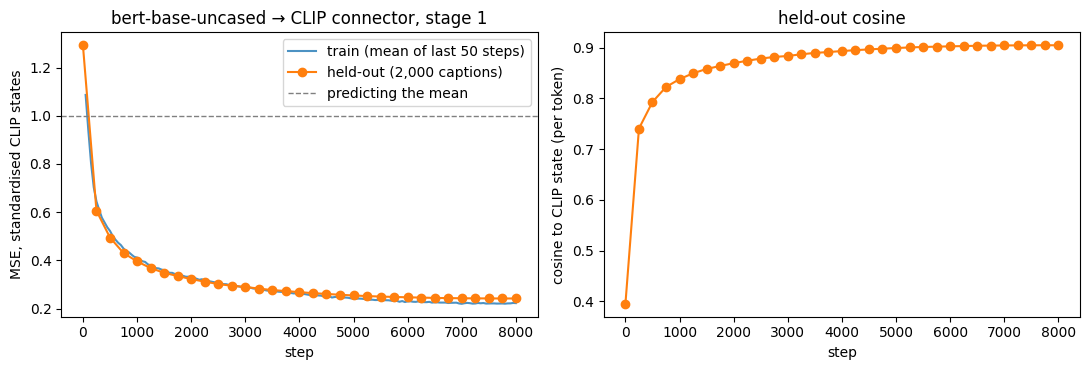

In [12]:
import matplotlib.pyplot as plt
L = pd.read_csv(f"{OUT}/training_log.csv"); H = L.dropna(subset=["heldout_loss"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(L.step, L.train_loss, label="train (mean of last 50 steps)", alpha=.8)
ax[0].plot(H.step, H.heldout_loss, "o-", label="held-out (2,000 captions)")
ax[0].axhline(1.0, ls="--", c="grey", lw=1, label="predicting the mean")
ax[0].set(xlabel="step", ylabel="MSE, standardised CLIP states", title=f"{CFG['encoder']} → CLIP connector, stage 1"); ax[0].legend()
ax[1].plot(H.step, H.heldout_cos, "o-", c="C1"); ax[1].set(xlabel="step", ylabel="cosine to CLIP state (per token)", title="held-out cosine")
plt.tight_layout(); plt.savefig(f"{OUT}/training_curve.png", dpi=160); plt.show()

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/396 [00:00<?, ?it/s]

top row: CLIP | bottom row: BERT → connector


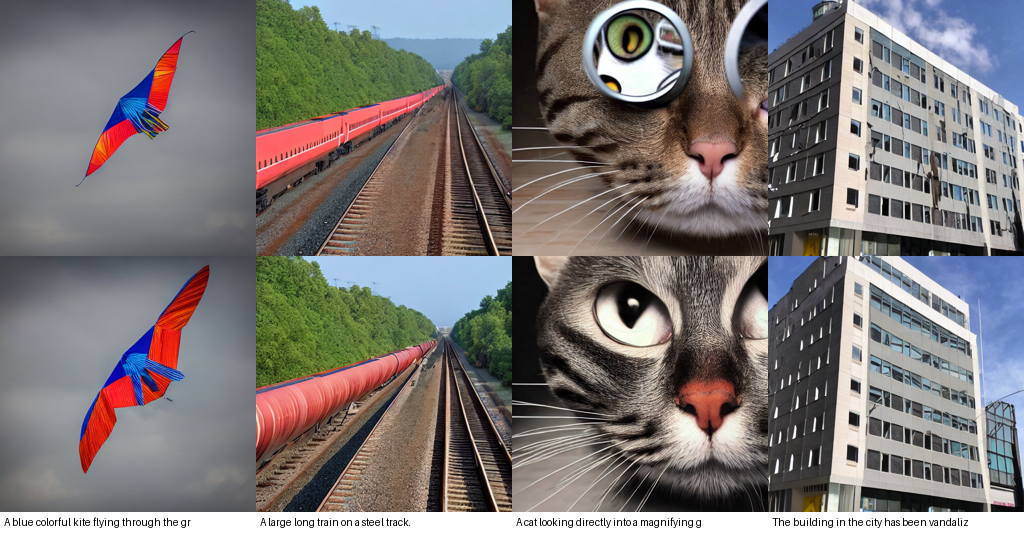

In [13]:
import m2_protocol as m2
pipe = m2.load_pipeline()
net.load_state_dict(torch.load(f"{OUT}/connector_best.pt")); net.eval()
dev = sc.load_split("dev_500").head(4); ne = clip_states([""]).half(); rows = []
for cap, idx in zip(dev.caption, dev.caption_idx):
    with torch.no_grad():
        h, m = enc_states([cap])
        with torch.autocast("cuda", torch.float16): pe = (net(h, m).float() * SD + MU).half()
    pair = []
    for emb in (clip_states([cap]).half(), pe):
        g = torch.Generator("cpu").manual_seed(int(idx))
        pair.append(pipe(prompt_embeds=emb, negative_prompt_embeds=ne, generator=g, num_inference_steps=30).images[0])
    rows.append((cap, pair))
from PIL import Image, ImageDraw
G = Image.new("RGB", (4 * 256, 2 * 256 + 40), "white"); d = ImageDraw.Draw(G)
for c, (cap, (a, b)) in enumerate(rows):
    G.paste(a.resize((256, 256)), (c * 256, 0)); G.paste(b.resize((256, 256)), (c * 256, 256))
    d.text((c * 256 + 4, 516), cap[:42], fill="black")
G.save(f"{OUT}/clip_vs_bert_samples.png"); print("top row: CLIP | bottom row: BERT → connector"); G

In [16]:
import os, subprocess
os.chdir("/kaggle/working")
subprocess.run('rm -f mukul_m2_everything.zip && zip -r -q mukul_m2_everything.zip m2 connector -x "m2/images/*"', shell=True)
print(f"zip size: {os.path.getsize('mukul_m2_everything.zip') / 1e6:.0f} MB")

from IPython.display import FileLink
FileLink("mukul_m2_everything.zip")

zip size: 206 MB


/kaggle/working/mukul_m2_everything.zip